# Linguagem × processamento da entrada — `code_language.png`

Mesmo gráfico de `graphic/code/grafico_linguagem_codigo.ipynb`. Os números vêm das colunas *Code language* e *Code route* de `../data/tabela_de_codigos_artefatos.csv`. Um estudo conta uma vez por linguagem citada.

Como no original, o gráfico mostra as nove linguagens nomeadas; os estudos com outra linguagem ou sem linguagem informada são contados na saída da célula de dados.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import dados_artefatos as da
from cores import ROTA

# como a entrada chega ao LLM: chave -> (rótulo da legenda, cor), na ordem de empilhamento
entradas = {"bruto": ROTA["CR2"], "ferramenta": ROTA["CR1"], "llm": ROTA["CR3"], "outros": ROTA["CR4"]}
_codigo = {"bruto": "CR2", "ferramenta": "CR1", "llm": "CR3", "outros": "CR4"}

In [2]:
# Estudos por linguagem (um estudo conta uma vez por linguagem citada), separados pela entrada
rotulos = {"LG1": "Java", "LG2": "Python", "LG3": "C/C++", "LG4": "JavaScript/\nTypeScript", "LG5": "Go", "LG6": "C#",
           "LG7": "Solidity", "LG8": "Rust", "LG9": "Kotlin"}
tabela = da.cruzamento("Code language", "Code route")
ordem = sorted(rotulos, key=lambda c: -tabela.loc[c].sum())      # barras em ordem decrescente
dados = [{"tipo": rotulos[c], **{k: int(tabela.loc[c, cod]) for k, cod in _codigo.items()}} for c in ordem]

x_pos = range(len(dados))
totais_barra = [sum(d[k] for k in entradas) for d in dados]
print(dict(zip([d["tipo"].replace(chr(10), "") for d in dados], totais_barra)))
print("fora do gráfico: outra linguagem =", int(tabela.loc["LG10"].sum()), "| não informada =", int(tabela.loc["LG0"].sum()))

{'Java': 98, 'Python': 80, 'C/C++': 26, 'JavaScript/TypeScript': 15, 'Go': 8, 'C#': 6, 'Rust': 5, 'Solidity': 3, 'Kotlin': 2}
fora do gráfico: outra linguagem = 23 | não informada = 46


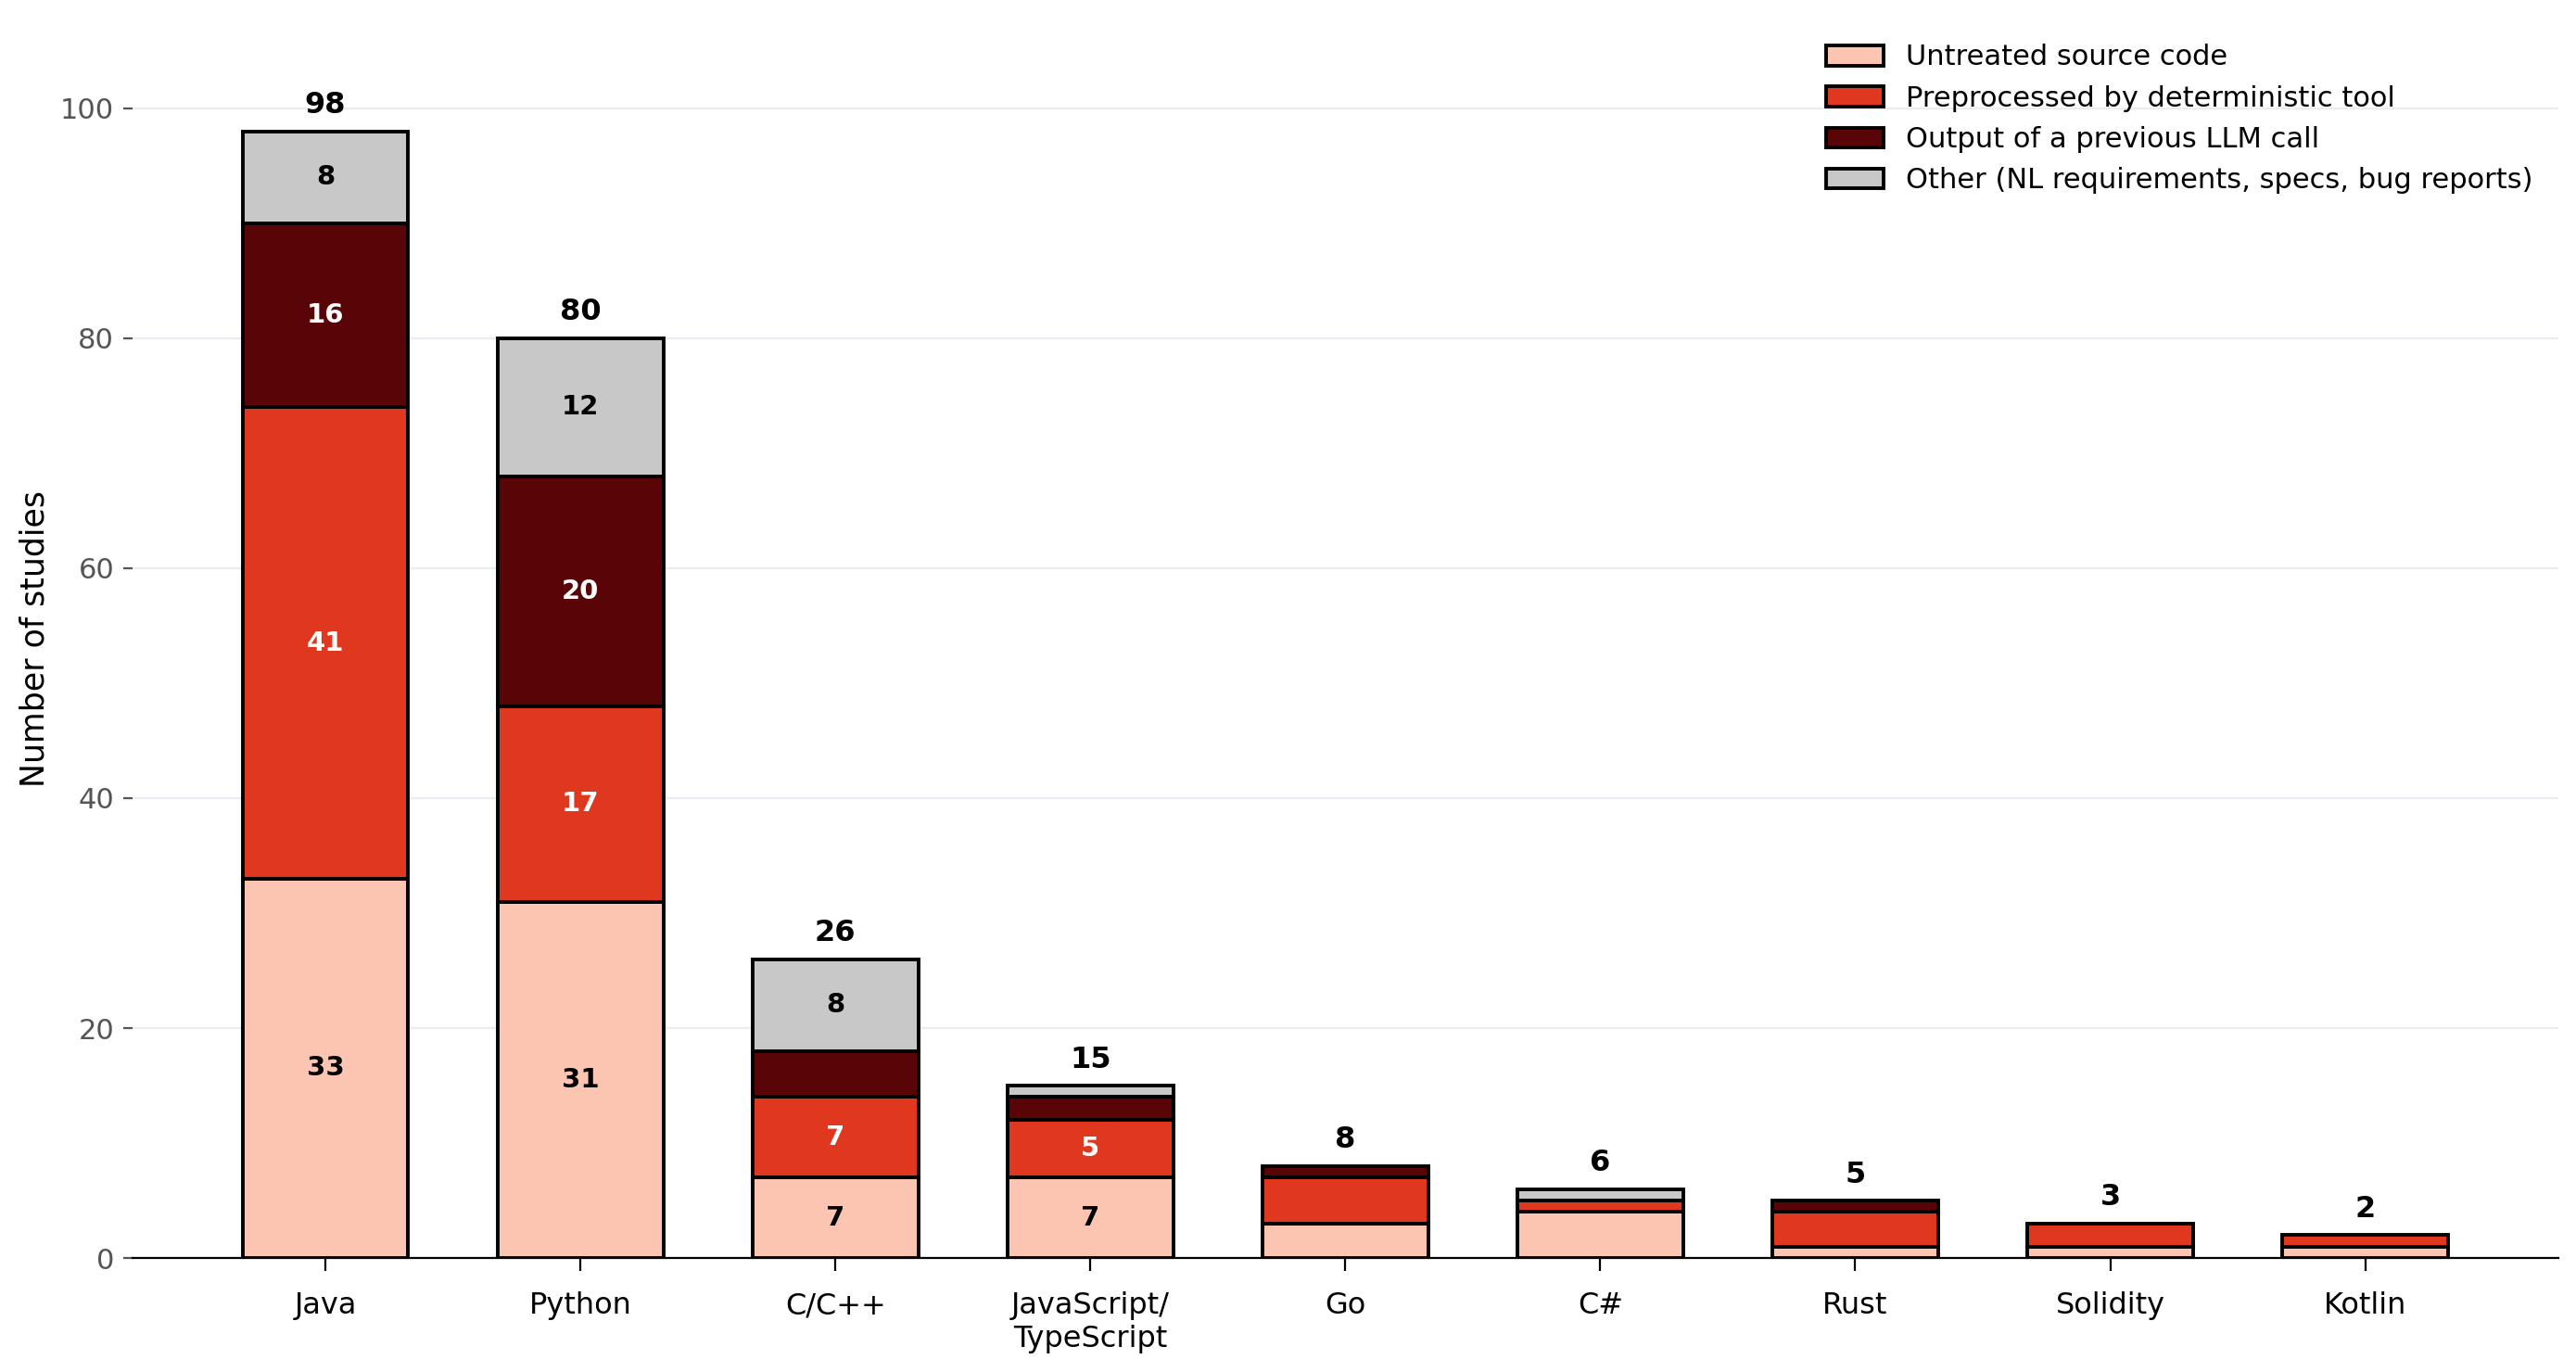

In [3]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

fig, ax = plt.subplots(figsize=(14, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for chave, (_, cor) in entradas.items():   # empilha sempre na ordem da legenda
        v = d[chave]
        if v == 0:
            continue
        ax.bar(x, v, bottom=base, color=cor, width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe
        if v >= 5:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4)
        base += v
    ax.text(x, base + 1, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=0, ha="center", fontsize=11.5)

ax.set_ylim(0, max(totais_barra) * 1.1)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", linewidth=1.4, label=nome)
    for nome, cor in entradas.values()
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig("code_language.png", bbox_inches="tight", dpi=200)
plt.savefig("code_language.pdf", bbox_inches="tight")
plt.show()